> ### Note on Labs and Assigments:
>
> 🔧 Look for the **wrench emoji** 🔧 — it highlights where you're expected to take action, write code (use AI as you need but cleanup the code)!

> These sections are graded and are not optional.
>

# **IS 4487 Assignment 7: Data Transformation with Airbnb Listings**

In this assignment, you will:
- Load the Airbnb dataset you cleaned in Assignment 6
- Apply data transformation techniques like scaling, binning, encoding, and feature creation
- Make the dataset easier to use for tasks like pricing analysis, guest segmentation, or listing recommendations
- Practice writing up your analysis clearly so a business audience — like a host, marketing manager, or city partner — could understand it

## Why This Matters

Airbnb analysts, hosts, and city partners rely on clean and well-structured data to make smart decisions. Whether they’re adjusting prices, identifying high-performing listings, or designing better guest experiences, they need data that’s transformed, organized, and ready for use.

This assignment helps you practice that kind of real-world thinking: taking messy real data and getting it ready for action.

<a href="https://colab.research.google.com/github/vandanara/UofUtah_IS4487/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

## **Task 1. Setup and Load Your Data**

1.1. Import the libraries you'll need for this assignment:
- `pandas`, `numpy` for data manipulation
- `matplotlib.pyplot`, `seaborn` for visualizations

You'll be working with the `cleaned_airbnb_data.csv` file you exported from Assignment 6.

1.2 In Google Colab:
- Click the folder icon on the left sidebar
- Use the upload button to add your CSV file to the session
- Then write code below to read it into your notebook



In [2]:
# 🔧 1.1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 🔧 1.2. Import saved dataset
df = pd.read_csv('/content/cleaned_airbnb_data.csv')

# Display the first few rows to verify successful loading
display(df.head())

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,2992450,https://www.airbnb.com/rooms/2992450,20260914164327,2026-09-16,NaN,Luxury 2 bedroom apartment,The apartment is located in a quiet neighborho...,NaN,https://a0.muscache.com/pictures/44627226/0e72...,4621559,...,4.22,4.56,3.22,3.67,NaN,1,1,0,0,0.06
1,3820211,https://www.airbnb.com/rooms/3820211,20260914164327,2026-09-16,NaN,Restored Precinct in Center Sq. w/Parking,Step into the charming and comfy 1BR/1BA apart...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,19648678,...,4.85,4.81,4.81,4.78,NaN,7,7,0,0,2.17
2,6623339,https://www.airbnb.com/rooms/6623339,20260914164327,2026-09-16,NaN,Center Sq. Loft in Converted Precinct w/ Parking,Step into the charming and comfy 1BR/1BA apart...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,19648678,...,4.83,4.72,4.79,4.73,NaN,7,7,0,0,2.50
3,9501054,https://www.airbnb.com/rooms/9501054,20260914164327,2026-09-16,NaN,Spacious suite with full bath by Capital Center,Great location within walking distance to the ...,NaN,https://a0.muscache.com/pictures/45153167-d704...,29288920,...,4.85,4.87,4.77,4.68,NaN,1,0,1,0,3.70
4,10768745,https://www.airbnb.com/rooms/10768745,20260914164327,2026-09-16,NaN,Alb hospital area studio bath wifi. (Red),Spacious warm studio in 1840 house close to ho...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,5691268,...,4.93,4.89,4.93,4.91,NaN,2,0,2,0,7.28


## **Task 2. Check for Skew in a Numeric Column**

Business framing:  

Airbnb listings can have a wide range of values for things like price, availability, or reviews. These kinds of distributions can be hard to visualize, summarize, or model.

Choose one **numeric column** that appears skewed and do the following:

2.1. Plot a histogram

2.2. Apply a transformation (e.g., log or other method)

2.3. Plot again to compare



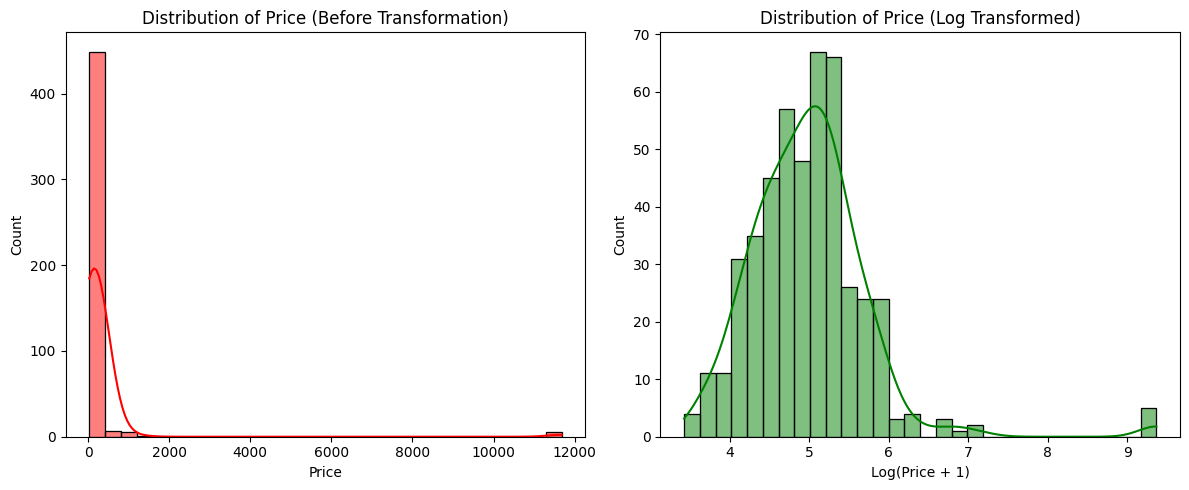

In [3]:
# 🔧 2.1. Add code here - show before histogram
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(df['price'], bins=30, kde=True, color='red')
plt.title('Distribution of Price (Before Transformation)')
plt.xlabel('Price')
plt.ylabel('Count')

# 🔧 2.2. Add code here
# Applying a log transformation (log1p to handle any potential zeros safely)
df['price_log'] = np.log1p(df['price'])

# 🔧 2.3. Add code here - show after histogram
plt.subplot(1, 2, 2)
sns.histplot(df['price_log'], bins=30, kde=True, color='green')
plt.title('Distribution of Price (Log Transformed)')
plt.xlabel('Log(Price + 1)')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

### ✍️ Please answer the following:

2.4. What column did you examine?

2.5. What transformation did you try, and why?

2.6. How did the transformed version help make the data more usable for analysis or stakeholder review?

### ✍️ Your Response:

2.4.
I examined the price column in the Airbnb dataset.

2.5.
I used log transformation (log(price + 1)) because the price data was very right-skewed and had some very high values.

2.6.
After the log transformation, the data looked more balanced and less skewed. It was easier to see the distribution of most prices because the very high prices had less effect on the graph.

## **Task 3. Scale Two Numeric Columns**

Business framing:

If an analyst wanted to compare listing price to number of nights required, or create a model that weighs both, those values need to be on a similar scale.

Follow these steps:
Pick two numeric columns with different value ranges (e.g. one column may have a min of 0 and a max of 255; another column may have a min of 100 and a max of 400). Apply two different types of scaling to them, and add these 2 new columns to the dataset with colnames ending in "_std" or "_norm"

3.1. Use Min-Max normalization on one column (range shoudl be 0-1)

3.2. Use Z-score standardization on the other column (mean should be 0 and var = 1)


3.3. Use .describe() to view the newly created variables before and after transformation.

In [4]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# 🔧 3.1. Min-Max normalization
min_max_scaler = MinMaxScaler()
df['minimum_nights_norm'] = min_max_scaler.fit_transform(df[['minimum_nights']])

# 🔧 3.2. Z-score standardization
std_scaler = StandardScaler()
df['price_std'] = std_scaler.fit_transform(df[['price']])

# 🔧 3.3 view the before and after variables
display(df[['minimum_nights', 'minimum_nights_norm', 'price', 'price_std']].describe())

,minimum_nights,minimum_nights_norm,price,price_std
count,499.000000,499.000000,467.000000,4.670000e+02
mean,6.793587,0.015916,292.594433,-2.282257e-17
std,19.584424,0.053803,1193.142209,1.001072e+00
min,1.000000,0.000000,29.800000,-2.204903e-01
25%,1.000000,0.000000,89.190000,-1.706608e-01
50%,2.000000,0.002747,144.000000,-1.246740e-01
75%,4.000000,0.008242,209.125000,-7.003268e-02
max,365.000000,1.000000,11680.000000,9.554282e+00


### ✍️ Please answer the following:

3.4. What two columns did you scale, and which methods did you use?

3.5. When might these scaled values be more useful than the originals?

3.6. Who at Airbnb might benefit from this transformation and why?

### ✍️ Your Response: 🔧

3.4. I used MinMaxScaler for minimum_nights and StandardScaler for price.

3.5. Scaling is useful when comparing different columns. For example, minimum_nights was changed to a range from 0 to 1, and price_std has a mean close to 0. This makes the data easier to compare.

3.6. Airbnb data analysts can use scaled data to compare prices and minimum nights. It can also help them build models to study Airbnb listings.



```
# This is formatted as code
```

## **Task 4. Bin a Numeric Column into Categories**

Business framing:  

Let’s say an Airbnb marketing team wants to segment listings by review activity. They don’t want exact numbers — they just want to know if a listing has “low,” “medium,” or “high” review volume.

4.1. Follow these steps:

- Choose a numeric column that could be grouped (e.g., reviews, availability).
- You’ll want to group the values of this column into 3 or 4 bins
- Create a new column. The values of this column will be the labels: “Low”, “Medium”, and “High.” These labels should correspond to your bins.

4.2. Output/view this column before and after transformation.



In [5]:
# 🔧 4.1. Choose 'number_of_reviews' and group into Low, Medium, High categories
# We'll use qcut to define 3 quantile-based bins
df['review_volume'] = pd.qcut(df['number_of_reviews'], q=3, labels=['Low', 'Medium', 'High'], duplicates='drop')

# 🔧 4.2. View the column before and after transformation
print("--- Before Binning: Sample of raw 'number_of_reviews' values ---")
print(df['number_of_reviews'].head(10))

print("\n--- After Binning: Value counts of the new 'review_volume' categories ---")
print(df['review_volume'].value_counts(dropna=False))

--- Before Binning: Sample of raw 'number_of_reviews' values ---
0      9
1    320
2    344
3    479
4    941
5    239
6    231
7     30
8    203
9     55
Name: number_of_reviews, dtype: int64

--- After Binning: Value counts of the new 'review_volume' categories ---
review_volume
Low       168
Medium    168
High      164
Name: count, dtype: int64


### ✍️ Please answer the following:

4.3. What column did you group, and how many categories did you use?

4.4. Why might someone prefer this grouped view over raw numbers?

4.5. Who would this help at Airbnb, and how?

### ✍️ Your Response: 🔧

4.3. I grouped number_of_reviews into three categories: Low, Medium, and High.

4.4. Grouping makes the data easier to understand. There are 168 listings in Low, 168 in Medium, and 164 in High. It is easier to compare these groups than looking at every review number.

4.5. Airbnb data analysts can use these groups to compare listings based on their number of reviews.

## **Task 5. Create Two New Business-Relevant Variables**

Business framing:  

Stakeholders often want to know things like: What’s the cost per night? Are listings geared toward long-term stays? These kinds of features aren’t always in the dataset — analysts create them.

Follow these steps:

5.1. - 5.2. Add two new columns to your DataFrame.
- Think of two new columns you can create or calculate using the data you already have.
  - One might be a ratio or interaction between columns (e.g., price ÷ nights).
  - The other might be a flag based on a condition (e.g., stays longer than 30 days).

5.3. View these new columns using .describe()



In [6]:
# 🔧 5.1. Create a ratio feature: price per accommodates
df['price_per_accommodates'] = df['price'] / df['accommodates']

# 🔧 5.2. Create a conditional flag feature: stays 30 days or longer
df['is_long_term_stay'] = (df['minimum_nights'] >= 30).astype(int)

# 🔧 5.3. View these new columns using .describe()
display(df[['price_per_accommodates', 'is_long_term_stay']].describe())

,price_per_accommodates,is_long_term_stay
count,467.000000,500.000000
mean,109.711898,0.058000
std,525.712417,0.233978
min,8.600000,0.000000
25%,37.956250,0.000000
50%,52.333333,0.000000
75%,71.875000,0.000000
max,5840.000000,1.000000


 ### ✍️ Please answer the following:

5.4. What two new columns did you create?

5.5. Who would use them (e.g., host, manager, or platform)?

5.6. How could they help someone make a better decision?


### ✍️ Your Response:

5.4. I created price_per_accommodates and is_long_term_stay.

5.5. Airbnb hosts and managers can use these columns.

5.6. Hosts can compare prices per person. The average price per person is about $109.71. They can also see which listings require at least 30 nights. This can help them make pricing decisions.



## **Task 6. Encode a Categorical Column**

Business framing:  

Let’s say you’re helping the Airbnb data science team build a model to predict booking rates. Categorical columns like `room_type`, `neighbourhood`, or `cancellation_policy` can’t be used in models unless they’re converted to numbers.

6.1. Do the following:
- Choose one categorical column from your dataset (e.g., room type or neighborhood group)
- Decide on an encoding method:
  - Use one-hot encoding for nominal (unordered) categories
  - Use ordinal encoding (a ranking) only if the categories have a clear order
- Apply the encoding
- Add the new encoded column(s) to your DataFrame

6.2. Display the encodings - the new variables.





In [7]:
# 🔧 6.1. Choose 'room_type' and apply One-Hot Encoding
room_type_encoded = pd.get_dummies(df['room_type'], prefix='room_type', dtype=int)

# Add the new encoded columns back to the DataFrame
df = pd.concat([df, room_type_encoded], axis=1)

# 🔧 6.2. Display the newly created encoded variables
display(df[room_type_encoded.columns].head())

,room_type_Entire home/apt,room_type_Private room,room_type_Shared room
0,1,0,0
1,1,0,0
2,1,0,0
3,0,1,0
4,0,1,0


### ✍️ Please answer the following:

6.3. What column did you encode and why?

6.4. What encoding method did you use?

6.5. How could this transformation help a pricing model, dashboard, or business report?

### ✍️ Your Response: 🔧

6.3. I encoded room_type to turn text into numbers.

6.4. I used One-Hot Encoding.

6.5. It helps pricing models compare prices for different room types.

## **Task 7. Reflection**

You’ve applied the same kinds of transformation techniques used in real Airbnb analytics projects — from pricing engines to host tools to tourism dashboards.

Now step back and reflect.

### ✍️ Please answer the following:

7.1. What transformation step felt most important or interesting?

7.2. Which of your changes would be most useful to a host, analyst, or city planner?

7.3. If you were going to build a tool or dashboard, what would you do next with this data?

7.4. How does this relate to your customized learning outcome you created in canvas?



### ✍️ Your Response: 🔧

7.1. I think log transformation was the most interesting. The highest price was $11,680, which is much higher than most prices. After log transformation, the graph was easier to read.

7.2. Price per person would be useful for hosts because it helps them compare prices.

7.3. I would create a dashboard to compare Airbnb prices and room types.

7.4. This relates to my learning outcome about cleaning and preparing data for analysis. It helps me understand how to make data more useful.



## **Task 8. Export Cleaned Data**

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 11**, where you'll use the data in a regression model.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_7.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```

In [8]:
# 🔧 Export the final transformed DataFrame to a CSV file
df.to_csv('cleaned_airbnb_data_7.csv', index=False)
print("Dataset exported successfully as 'cleaned_airbnb_data_7.csv'!")

Dataset exported successfully as 'cleaned_airbnb_data_7.csv'!


## Submission Instructions
✅ Checklist:
- Make sure all code cells are run and outputs are visible  
- All markdown/comment questions are answered thoughtfully  
- Save the file with your last name and first name as shown below (see detailed instructions in Lab 1 on how to do this).
- Submit the assignment as an **HTML file** on Canvas

In [9]:
!jupyter nbconvert --to html "assignment_07_Gong Linlin.ipynb"

[NbConvertApp] Converting notebook assignment_07_Gong Linlin.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 390477 bytes to assignment_07_Gong Linlin.html
